# Analyse de portefeuille — clôtures au 31 décembre

| Paramètre | Valeur |
| --- | --- |
| Tickers | `WPEA.PA`, `EN.PA`, `PAEEM.PA`, `WSML.L` |
| Poids | 25 % chacun |
| WACC | 8 % (fixe) |
| ROCE | rendement annuel moyen arithmétique du portefeuille |
| Spread net | ROCE − WACC |

Le **31 décembre** n'est pas toujours un jour de Bourse : on retient le **dernier cours de clôture coté de l'année civile**.  
Cinq clôtures (fin 2021 → fin 2025) donnent **4 rendements annuels**.  
`WSML.L` est coté à Londres (rendements en devise locale).  
`WPEA.PA` n'a d'historique Yahoo Finance qu'à partir d'avril 2024 : les clôtures antérieures restent vides.

In [27]:
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from IPython.display import Markdown, display

%matplotlib inline

TICKERS = ["WPEA.PA", "EN.PA", "PAEEM.PA", "WSML.L"]
POIDS = pd.Series(0.25, index=TICKERS, name="Poids")
WACC = 0.08
N_ANNEES = 4

annee_ref = datetime.now().year - 1  # dernière année civile close
annees_cloture = list(range(annee_ref - N_ANNEES, annee_ref + 1))


def extraire_close(df: pd.DataFrame, ticker: str) -> pd.Series:
    if isinstance(df.columns, pd.MultiIndex):
        close = df["Close"]
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
    else:
        close = df["Close"]
    close.name = ticker
    return close.sort_index()


def clotures_31_decembre(serie: pd.Series, annees: list[int]) -> tuple[pd.Series, pd.Series]:
    prix, jours = {}, {}
    for annee in annees:
        fin = pd.Timestamp(f"{annee}-12-31")
        historique = serie.loc[:fin].dropna()
        if historique.empty:
            prix[annee] = np.nan
            jours[annee] = pd.NaT
        else:
            prix[annee] = float(historique.iloc[-1])
            jours[annee] = historique.index[-1].normalize()
    return pd.Series(prix, name=serie.name), pd.Series(jours, name=serie.name)


def formater_pct(obj: pd.DataFrame | pd.Series) -> pd.DataFrame | pd.Series:
    return obj.map(lambda x: f"{x:.2%}" if pd.notna(x) else "—")


def afficher_tableau(titre: str, df: pd.DataFrame) -> None:
    display(Markdown(f"### {titre}"))
    display(df)

In [28]:
debut = f"{annees_cloture[0]}-11-01"
fin = f"{annees_cloture[-1] + 1}-01-10"  # yfinance exclut la date de fin

series_quotidiennes = {}
for ticker in TICKERS:
    brut = yf.download(
        ticker,
        start=debut,
        end=fin,
        auto_adjust=True,
        progress=False,
        threads=False,
    )
    if brut.empty:
        raise RuntimeError(f"Aucun cours téléchargé pour {ticker}.")
    series_quotidiennes[ticker] = extraire_close(brut, ticker)

prix_par_actif, jours_par_actif = {}, {}
for ticker, serie in series_quotidiennes.items():
    prix, jours = clotures_31_decembre(serie, annees_cloture)
    prix_par_actif[ticker] = prix
    jours_par_actif[ticker] = jours

clotures = pd.DataFrame(prix_par_actif)
clotures.index.name = "Année"
jours_cotes = pd.DataFrame(jours_par_actif)
jours_cotes.index.name = "Année"

prix_fmt = clotures.map(lambda x: f"{x:,.4f}" if pd.notna(x) else "—")
jours_fmt = jours_cotes.map(lambda d: d.strftime("%Y-%m-%d") if pd.notna(d) else "—")

afficher_tableau("Prix de clôture de fin d'année", prix_fmt)
afficher_tableau("Date réelle du dernier cours de l'année", jours_fmt)

### Prix de clôture de fin d'année

,WPEA.PA,EN.PA,PAEEM.PA,WSML.L
Année,,,,
2021,—,24.2426,23.6830,7.3970
2022,—,22.8631,20.0560,6.0200
2023,—,29.4412,20.7080,7.0470
2024,5.7256,25.9763,23.4100,7.5685
2025,6.1178,42.5458,28.6700,9.0780


### Date réelle du dernier cours de l'année

,WPEA.PA,EN.PA,PAEEM.PA,WSML.L
Année,,,,
2021,—,2021-12-31,2021-12-31,2021-12-31
2022,—,2022-12-30,2022-12-30,2022-12-30
2023,—,2023-12-29,2023-12-29,2023-12-29
2024,2024-12-31,2024-12-31,2024-12-31,2024-12-31
2025,2025-12-24,2025-12-31,2025-12-31,2025-12-31


In [29]:
rendements = clotures.pct_change()
rendements = rendements.iloc[1:]  # première ligne = NaN (pas d'année précédente)
rendements.index = [f"{int(annee) - 1} → {int(annee)}" for annee in rendements.index]
rendements.index.name = "Période"

afficher_tableau("Rendements annuels", formater_pct(rendements))

### Rendements annuels

,WPEA.PA,EN.PA,PAEEM.PA,WSML.L
Période,,,,
2021 → 2022,—,-5.69%,-15.31%,-18.62%
2022 → 2023,—,28.77%,3.25%,17.06%
2023 → 2024,—,-11.77%,13.05%,7.40%
2024 → 2025,6.85%,63.79%,22.47%,19.94%


In [30]:
# Variance et volatilité échantillonnales (ddof=1) sur les rendements annuels
stats_actifs = pd.DataFrame(
    {
        "Poids": POIDS,
        "Rendement annuel moyen": rendements.mean(skipna=True),
        "Variance": rendements.var(ddof=1, skipna=True),
        "Volatilité (écart-type)": rendements.std(ddof=1, skipna=True),
        "Nb rendements": rendements.notna().sum(),
    }
)

stats_fmt = pd.DataFrame(
    {
        "Poids": stats_actifs["Poids"].map("{:.0%}".format),
        "Rendement annuel moyen": stats_actifs["Rendement annuel moyen"].map(
            lambda x: f"{x:.2%}" if pd.notna(x) else "—"
        ),
        "Variance": stats_actifs["Variance"].map(
            lambda x: f"{x:.6f}" if pd.notna(x) else "—"
        ),
        "Volatilité (écart-type)": stats_actifs["Volatilité (écart-type)"].map(
            lambda x: f"{x:.2%}" if pd.notna(x) else "—"
        ),
        "Nb rendements": stats_actifs["Nb rendements"].astype(int),
    }
)
stats_fmt.index.name = "Ticker"

afficher_tableau("Statistiques par actif", stats_fmt)

### Statistiques par actif

,Poids,Rendement annuel moyen,Variance,Volatilité (écart-type),Nb rendements
Ticker,,,,,
WPEA.PA,25%,6.85%,—,—,1
EN.PA,25%,18.77%,0.121915,34.92%,4
PAEEM.PA,25%,5.86%,0.026090,16.15%,4
WSML.L,25%,6.45%,0.030795,17.55%,4


In [31]:
matrice_cov = rendements.cov(ddof=1, min_periods=2)
matrice_corr = rendements.corr(min_periods=2)

afficher_tableau(
    "Matrice de covariance (rendements annuels)",
    matrice_cov.map(lambda x: f"{x:.6f}" if pd.notna(x) else "—"),
)
afficher_tableau(
    "Matrice de corrélation (complément)",
    matrice_corr.map(lambda x: f"{x:.2f}" if pd.notna(x) else "—"),
)

### Matrice de covariance (rendements annuels)

,WPEA.PA,EN.PA,PAEEM.PA,WSML.L
WPEA.PA,—,—,—,—
EN.PA,—,0.121915,0.034001,0.043256
PAEEM.PA,—,0.034001,0.026090,0.024468
WSML.L,—,0.043256,0.024468,0.030795


### Matrice de corrélation (complément)

,WPEA.PA,EN.PA,PAEEM.PA,WSML.L
WPEA.PA,—,—,—,—
EN.PA,—,1.00,0.60,0.71
PAEEM.PA,—,0.60,1.00,0.86
WSML.L,—,0.71,0.86,1.00


### Rendements annuels du portefeuille équipondéré

,Rendement du portefeuille
Période,
2024 → 2025,28.26%


### ROCE, WACC et spread net

,Valeur
Indicateur,
WACC (fixe),8.00%
ROCE global (rendement annuel moyen du portefeuille),28.26%
Spread net (ROCE − WACC),20.26%
Volatilité du portefeuille,—
Nb d'années utilisées (4 actifs cotés),1


**Lecture :** Le portefeuille crée de la valeur : le ROCE (28.26%) dépasse le WACC (8.00%) de 20.26%.

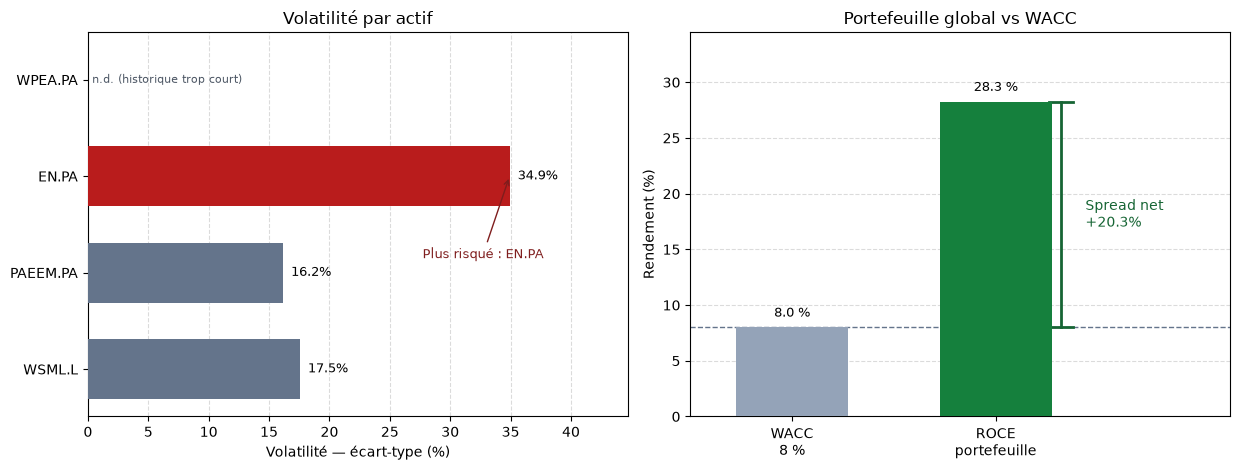

In [32]:
w = POIDS.reindex(rendements.columns).values

# Années où les 4 lignes sont cotées : portefeuille réellement équipondéré 25/25/25/25
rendements_complets = rendements.dropna(how="any")
r_port_annuel = rendements_complets @ w
roce = float(r_port_annuel.mean()) if len(r_port_annuel) else np.nan
spread = roce - WACC if pd.notna(roce) else np.nan

if len(rendements_complets) >= 2:
    cov_complete = rendements_complets.cov(ddof=1)
    vol_port = float(np.sqrt(w @ cov_complete.values @ w))
else:
    vol_port = np.nan

detail_port = pd.DataFrame({"Rendement du portefeuille": r_port_annuel})
detail_port.index.name = "Période"

synthese = pd.DataFrame(
    {
        "Indicateur": [
            "WACC (fixe)",
            "ROCE global (rendement annuel moyen du portefeuille)",
            "Spread net (ROCE − WACC)",
            "Volatilité du portefeuille",
            "Nb d'années utilisées (4 actifs cotés)",
        ],
        "Valeur": [
            f"{WACC:.2%}",
            f"{roce:.2%}" if pd.notna(roce) else "—",
            f"{spread:.2%}" if pd.notna(spread) else "—",
            f"{vol_port:.2%}" if pd.notna(vol_port) else "—",
            str(len(r_port_annuel)),
        ],
    }
).set_index("Indicateur")

afficher_tableau(
    "Rendements annuels du portefeuille équipondéré",
    formater_pct(detail_port),
)
afficher_tableau("ROCE, WACC et spread net", synthese)

if pd.isna(roce):
    verdict = (
        "Impossible de calculer le ROCE équipondéré : aucune année où les 4 actifs "
        "ont simultanément un rendement."
    )
elif spread >= 0:
    verdict = (
        f"Le portefeuille crée de la valeur : le ROCE ({roce:.2%}) "
        f"dépasse le WACC ({WACC:.2%}) de {spread:.2%}."
    )
else:
    verdict = (
        f"Le portefeuille détruit de la valeur : le ROCE ({roce:.2%}) "
        f"est inférieur au WACC ({WACC:.2%}) de {abs(spread):.2%}."
    )

display(Markdown(f"**Lecture :** {verdict}"))

fig, (ax_vol, ax_spread) = plt.subplots(1, 2, figsize=(12.5, 4.8))

vol = stats_actifs["Volatilité (écart-type)"]
vol_plot = vol.fillna(0.0)
plus_risque = vol.idxmax() if vol.notna().any() else None
couleurs_vol = []
for ticker, v in vol.items():
    if pd.isna(v):
        couleurs_vol.append("#9ca3af")
    elif ticker == plus_risque:
        couleurs_vol.append("#b91c1c")
    else:
        couleurs_vol.append("#64748b")

y_pos = np.arange(len(vol_plot))
ax_vol.barh(y_pos, vol_plot.values * 100, color=couleurs_vol, height=0.62, zorder=3)
ax_vol.set_yticks(y_pos)
ax_vol.set_yticklabels(list(vol_plot.index))
ax_vol.invert_yaxis()
ax_vol.set_xlabel("Volatilité — écart-type (%)")
ax_vol.set_title("Volatilité par actif")
ax_vol.grid(axis="x", linestyle="--", alpha=0.45, zorder=0)
ax_vol.set_axisbelow(True)
xmax = max(vol.dropna().max() * 100 if vol.notna().any() else 1, 1) * 1.28
ax_vol.set_xlim(0, xmax)
for i, (ticker, v) in enumerate(vol.items()):
    if pd.isna(v):
        ax_vol.text(0.35, i, "n.d. (historique trop court)", va="center", fontsize=8, color="#4b5563")
    else:
        ax_vol.text(v * 100 + xmax * 0.015, i, f"{v:.1%}", va="center", fontsize=9)
if plus_risque is not None:
    ax_vol.annotate(
        f"Plus risqué : {plus_risque}",
        xy=(vol[plus_risque] * 100, list(vol.index).index(plus_risque)),
        xytext=(xmax * 0.62, list(vol.index).index(plus_risque) + 0.85),
        fontsize=9,
        color="#7f1d1d",
        arrowprops=dict(arrowstyle="->", color="#7f1d1d"),
    )

labels_spread = ["WACC\n8 %", "ROCE\nportefeuille"]
valeurs_spread = [WACC * 100, roce * 100] if pd.notna(roce) else [WACC * 100, 0.0]
couleur_roce = "#15803d" if pd.notna(spread) and spread >= 0 else "#b91c1c"
barres = ax_spread.bar(
    labels_spread,
    valeurs_spread,
    color=["#94a3b8", couleur_roce],
    width=0.55,
    zorder=3,
)
ax_spread.axhline(WACC * 100, color="#64748b", linestyle="--", linewidth=1, zorder=2)
ax_spread.set_ylabel("Rendement (%)")
ax_spread.set_title("Portefeuille global vs WACC")
ax_spread.grid(axis="y", linestyle="--", alpha=0.45, zorder=0)
ax_spread.set_axisbelow(True)
ymax = max(valeurs_spread + [WACC * 100]) * 1.22
ax_spread.set_ylim(0, ymax)
for barre, val in zip(barres, valeurs_spread):
    ax_spread.text(
        barre.get_x() + barre.get_width() / 2,
        val + ymax * 0.02,
        f"{val:.1f} %",
        ha="center",
        va="bottom",
        fontsize=9,
    )
if pd.notna(spread) and pd.notna(roce):
    x_acc = 1.32
    ax_spread.plot([x_acc, x_acc], [WACC * 100, roce * 100], color="#166534", linewidth=2, zorder=4)
    ax_spread.plot([x_acc - 0.06, x_acc + 0.06], [WACC * 100, WACC * 100], color="#166534", linewidth=2)
    ax_spread.plot([x_acc - 0.06, x_acc + 0.06], [roce * 100, roce * 100], color="#166534", linewidth=2)
    ax_spread.text(
        x_acc + 0.12,
        (WACC + roce) / 2 * 100,
        f"Spread net\n{spread:+.1%}",
        va="center",
        ha="left",
        fontsize=10,
        color="#166534",
        fontweight="medium",
    )
    ax_spread.set_xlim(-0.5, 2.15)

fig.tight_layout()
plt.show()

## Simulation Core-Satellite — rapport décisionnel

Projection sur **10 ans** à compter du **01-11-2026**, avec un DCA de **1 000 € / mois** (70 % Core `WPEA.PA`, 10 % `WSML.L`, 15 % `PAEEM.PA`, 5 % `EN.PA`).  
Le moteur de calcul (CAPM / MEDAF, bêtas Yahoo Finance, capitalisation mensuelle) est masqué : seules les conclusions sont affichées.

In [ ]:
from IPython.display import HTML, Markdown, display

display(HTML("""
<style>
.jp-CodeCell:has(.rapport-core-satellite) .jp-Cell-inputWrapper,
.jp-CodeCell:has(.rapport-core-satellite) .jp-Editor,
.cell.code:has(.rapport-core-satellite) .input {
    display: none !important;
}
</style>
<div class="rapport-core-satellite"></div>
"""))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

%matplotlib inline

DATE_DEBUT = pd.Timestamp("2026-11-01")
HORIZON_ANNEES = 10
N_MOIS = HORIZON_ANNEES * 12
VERSEMENT_MENSUEL = 1_000.0
TAUX_SANS_RISQUE = 0.03
PRIME_RISQUE_MARCHE = 0.055
MARCHE_PROXY = "URTH"  # iShares MSCI World, proxy β OLS
BETA_DEFAUT_WPEA = 1.0

CAPITAL_INITIAL = pd.Series(
    {
        "WPEA.PA": 6_000.0,
        "WSML.L": 2_500.0,
        "PAEEM.PA": 2_500.0,
        "EN.PA": 1_300.0,
    },
    name="Capital initial",
)
TICKERS_SIM = list(CAPITAL_INITIAL.index)

POIDS_DCA = pd.Series(
    {
        "WPEA.PA": 0.70,
        "WSML.L": 0.10,
        "PAEEM.PA": 0.15,
        "EN.PA": 0.05,
    }
).reindex(TICKERS_SIM)

NOMS = {
    "WPEA.PA": "iShares MSCI World PEA (Core)",
    "WSML.L": "iShares MSCI World Small Caps",
    "PAEEM.PA": "Amundi PEA Émergents",
    "EN.PA": "Bouygues SA",
}


def formater_eur(x: float, decimales: int = 0) -> str:
    if pd.isna(x):
        return "—"
    texte = f"{x:,.{decimales}f}"
    return texte.replace(",", " ").replace(".", ",") + " €"


def formater_pct(x: float, decimales: int = 2) -> str:
    if pd.isna(x):
        return "—"
    return f"{x:.{decimales}%}".replace(".", ",")


def extraire_info(ticker: str) -> dict:
    try:
        info = yf.Ticker(ticker).info
        return info if isinstance(info, dict) else {}
    except Exception:
        return {}


def beta_yahoo(info: dict) -> tuple[float | None, str | None]:
    for cle in ("beta", "beta3Year"):
        val = info.get(cle)
        try:
            beta = float(val)
        except (TypeError, ValueError):
            continue
        if np.isfinite(beta):
            return beta, f"Yahoo Finance ({cle})"
    return None, None


def extraire_close_local(df: pd.DataFrame, ticker: str) -> pd.Series:
    if df is None or df.empty:
        return pd.Series(dtype=float, name=ticker)
    if isinstance(df.columns, pd.MultiIndex):
        close = df["Close"]
        if isinstance(close, pd.DataFrame):
            if ticker in close.columns:
                close = close[ticker]
            else:
                close = close.iloc[:, 0]
    else:
        close = df["Close"]
    close = close.dropna().sort_index()
    close.name = ticker
    return close


def beta_ols(ticker: str, marche: str = MARCHE_PROXY, period: str = "5y") -> float | None:
    try:
        brut = yf.download(
            [ticker, marche],
            period=period,
            auto_adjust=True,
            progress=False,
            threads=False,
            group_by="ticker",
        )
    except Exception:
        return None
    if brut is None or brut.empty:
        return None
    try:
        if isinstance(brut.columns, pd.MultiIndex):
            y = extraire_close_local(brut[ticker] if ticker in brut.columns.get_level_values(0) else brut, ticker)
            x = extraire_close_local(brut[marche] if marche in brut.columns.get_level_values(0) else brut, marche)
        else:
            return None
        rendements = pd.concat([y, x], axis=1).dropna().pct_change().dropna()
        if len(rendements) < 60:
            return None
        y_r = rendements.iloc[:, 0].to_numpy(dtype=float)
        x_r = rendements.iloc[:, 1].to_numpy(dtype=float)
        var_x = float(np.var(x_r, ddof=1))
        if var_x <= 0:
            return None
        cov_xy = float(np.cov(y_r, x_r, ddof=1)[0, 1])
        beta = cov_xy / var_x
        return float(beta) if np.isfinite(beta) else None
    except Exception:
        return None


def extraire_beta(ticker: str) -> tuple[float, str]:
    info = extraire_info(ticker)
    beta, source = beta_yahoo(info)
    if beta is not None:
        return beta, source
    if ticker == "WPEA.PA":
        return BETA_DEFAUT_WPEA, "défaut indice mondial (β = 1,0)"
    beta_reg = beta_ols(ticker)
    if beta_reg is not None:
        return beta_reg, f"OLS 5 ans vs {MARCHE_PROXY}"
    return np.nan, "indisponible"


def variance_historique_actifs(tickers: list[str]) -> pd.Series:
    if "stats_actifs" in globals():
        var = stats_actifs["Variance"].reindex(tickers)
        if var.notna().any():
            return var
    if "rendements" in globals():
        return rendements.reindex(columns=tickers).var(ddof=1, skipna=True)
    return pd.Series(np.nan, index=tickers, name="Variance")


if not np.isclose(float(POIDS_DCA.sum()), 1.0):
    raise ValueError(f"Les poids DCA doivent sommer à 100 % (actuel : {POIDS_DCA.sum():.2%}).")

betas = {}
sources_beta = {}
for ticker in TICKERS_SIM:
    beta, source = extraire_beta(ticker)
    betas[ticker] = beta
    sources_beta[ticker] = source

betas = pd.Series(betas, name="Bêta")
rendements_capm = TAUX_SANS_RISQUE + betas * PRIME_RISQUE_MARCHE
rendements_capm.name = "E(R) CAPM"
taux_mensuels = (1.0 + rendements_capm) ** (1.0 / 12.0) - 1.0

if rendements_capm.isna().any():
    manquants = list(rendements_capm[rendements_capm.isna()].index)
    raise RuntimeError(f"Impossible de calculer le CAPM (bêta manquant) pour : {manquants}")

dates = pd.date_range(DATE_DEBUT, periods=N_MOIS + 1, freq="MS")
encours = pd.DataFrame(0.0, index=dates, columns=TICKERS_SIM)
encours.iloc[0] = CAPITAL_INITIAL + POIDS_DCA * VERSEMENT_MENSUEL

facteurs_twrr = []
for i in range(1, len(dates)):
    avant = encours.iloc[i - 1]
    apres_croissance = avant * (1.0 + taux_mensuels)
    facteurs_twrr.append(float(apres_croissance.sum() / avant.sum()))
    encours.iloc[i] = apres_croissance
    if i < N_MOIS:
        encours.iloc[i] = encours.iloc[i] + POIDS_DCA * VERSEMENT_MENSUEL

valeur_totale = encours.sum(axis=1)
poids_dynamiques = encours.div(valeur_totale, axis=0)
er_periodique = poids_dynamiques @ rendements_capm

n_versements = N_MOIS
total_verse = float(CAPITAL_INITIAL.sum() + n_versements * VERSEMENT_MENSUEL)
valeur_finale = float(valeur_totale.iloc[-1])
interets_generes = valeur_finale - total_verse

produit_twrr = float(np.prod(facteurs_twrr))
twrr_annuel = produit_twrr ** (12.0 / N_MOIS) - 1.0
er_cible_dca = float(POIDS_DCA @ rendements_capm)
er_initial = float(er_periodique.iloc[0])
er_final = float(er_periodique.iloc[-1])
er_moyen_temps = float(er_periodique.mean())

variances = variance_historique_actifs(TICKERS_SIM)

fiche_actifs = pd.DataFrame(
    {
        "Actif": [NOMS[t] for t in TICKERS_SIM],
        "Bêta": betas.map(lambda x: f"{x:.2f}".replace(".", ",") if pd.notna(x) else "—"),
        "Source du bêta": pd.Series(sources_beta),
        "E(R) CAPM annuel": rendements_capm.map(lambda x: formater_pct(x)),
        "Taux mensuel composé": taux_mensuels.map(lambda x: formater_pct(x, 3)),
        "Poids DCA": POIDS_DCA.map(lambda x: formater_pct(x, 0)),
        "Capital au 01-11-2026": CAPITAL_INITIAL.map(lambda x: formater_eur(x)),
        "Valeur finale": encours.iloc[-1].map(lambda x: formater_eur(x)),
        "Variance historique": variances.map(lambda x: f"{x:.6f}" if pd.notna(x) else "n.d."),
    }
)
fiche_actifs.index = TICKERS_SIM
fiche_actifs.index.name = "Ticker"

poids_cles = pd.DataFrame(
    {
        "01-11-2026 (départ)": poids_dynamiques.iloc[0],
        "01-11-2031 (5 ans)": poids_dynamiques.iloc[60] if len(poids_dynamiques) > 60 else np.nan,
        "01-11-2036 (10 ans)": poids_dynamiques.iloc[-1],
        "Cible DCA": POIDS_DCA,
    }
).map(lambda x: formater_pct(x, 1) if pd.notna(x) else "—")
poids_cles.index.name = "Ticker"

synthese_sim = pd.DataFrame(
    {
        "Indicateur": [
            "Date de départ",
            "Horizon",
            "Versement mensuel",
            "Nombre de versements",
            "Capital initial",
            "Total des versements DCA",
            "Encours investi cumulé",
            "Valeur finale du portefeuille",
            "Intérêts composés (CAPM)",
            "Taux sans risque",
            "Prime de risque de marché",
            "E(R) mix de départ (pondération réelle)",
            "E(R) cible DCA 70/10/15/5",
            "E(R) moyen dans le temps (pondération dynamique)",
            "E(R) mix final",
            "TWRR théorique annualisé (ROCE projeté)",
        ],
        "Valeur": [
            DATE_DEBUT.strftime("%d-%m-%Y"),
            f"{HORIZON_ANNEES} ans ({N_MOIS} mois)",
            formater_eur(VERSEMENT_MENSUEL),
            str(n_versements),
            formater_eur(float(CAPITAL_INITIAL.sum())),
            formater_eur(n_versements * VERSEMENT_MENSUEL),
            formater_eur(total_verse),
            formater_eur(valeur_finale),
            formater_eur(interets_generes),
            formater_pct(TAUX_SANS_RISQUE),
            formater_pct(PRIME_RISQUE_MARCHE),
            formater_pct(er_initial),
            formater_pct(er_cible_dca),
            formater_pct(er_moyen_temps),
            formater_pct(er_final),
            formater_pct(twrr_annuel),
        ],
    }
).set_index("Indicateur")

multiple_capital = valeur_finale / total_verse if total_verse else np.nan
if twrr_annuel >= TAUX_SANS_RISQUE + 0.02:
    verdict = (
        f"Le mix Core-Satellite génère un TWRR théorique de **{formater_pct(twrr_annuel)}** "
        f"(ROCE projeté via CAPM). Sur 10 ans, les intérêts composés représentent "
        f"**{formater_eur(interets_generes)}**, soit un multiple de **{multiple_capital:.2f}x** "
        f"du capital investi. La pondération dynamique du DCA (70 % World) tire progressivement "
        f"le rendement attendu vers **{formater_pct(er_cible_dca)}**."
    )
else:
    verdict = (
        f"Le TWRR théorique ({formater_pct(twrr_annuel)}) reste proche du taux sans risque. "
        f"Revoir les bêtas extraits ou la répartition satellite avant d'augmenter le rythme de versement."
    )
display(Markdown("### 1. Bêtas extraits et rendements CAPM par actif"))
display(Markdown(
    f"Formule : $E(R_i) = {TAUX_SANS_RISQUE:.1%} + \\beta_i \\times {PRIME_RISQUE_MARCHE:.1%}$. "
    "Si le bêta Yahoo de `WPEA.PA` est absent, $\\beta = 1{,}0$ (indice mondial)."
))
display(fiche_actifs)

display(Markdown("### 2. Pondération dynamique (départ → cible DCA)"))
display(poids_cles)

display(Markdown("### 3. Synthèse de la capitalisation mensuelle sur 10 ans"))
display(synthese_sim)
display(Markdown(f"**Lecture décisionnelle :** {verdict}"))

fig, (ax_croissance, ax_var) = plt.subplots(1, 2, figsize=(13.2, 5.0))

ax_croissance.plot(
    valeur_totale.index,
    valeur_totale.values,
    color="#0f4c81",
    linewidth=2.4,
    label="Valeur du portefeuille (CAPM)",
    zorder=3,
)
cumul_investi = pd.Series(
    float(CAPITAL_INITIAL.sum())
    + np.minimum(np.arange(len(dates)) + 1, n_versements) * VERSEMENT_MENSUEL,
    index=dates,
)
ax_croissance.plot(
    cumul_investi.index,
    cumul_investi.values,
    color="#94a3b8",
    linewidth=1.6,
    linestyle="--",
    label="Capital investi cumulé",
    zorder=2,
)
ax_croissance.fill_between(
    valeur_totale.index,
    cumul_investi.values,
    valeur_totale.values,
    color="#0f4c81",
    alpha=0.12,
    label="Intérêts composés",
)
ax_croissance.set_title("Croissance cumulative de la richesse")
ax_croissance.set_xlabel("Date")
ax_croissance.set_ylabel("Euros")
ax_croissance.grid(True, linestyle="--", alpha=0.45, zorder=0)
ax_croissance.set_axisbelow(True)
ax_croissance.legend(frameon=False, loc="upper left")
ax_croissance.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v/1000:.0f} k€" if abs(v) >= 1000 else f"{v:.0f} €")
)
ax_croissance.annotate(
    formater_eur(valeur_finale),
    xy=(valeur_totale.index[-1], valeur_finale),
    xytext=(-86, 12),
    textcoords="offset points",
    fontsize=9,
    color="#0f4c81",
    fontweight="medium",
)

var_plot = variances.fillna(0.0)
plus_var = variances.idxmax() if variances.notna().any() else None
couleurs = []
for ticker, v in variances.items():
    if pd.isna(v):
        couleurs.append("#9ca3af")
    elif ticker == plus_var:
        couleurs.append("#b91c1c")
    else:
        couleurs.append("#64748b")

x_pos = np.arange(len(var_plot))
ax_var.bar(x_pos, var_plot.values, color=couleurs, width=0.62, zorder=3)
ax_var.set_xticks(x_pos)
ax_var.set_xticklabels(list(var_plot.index), rotation=15, ha="right")
ax_var.set_ylabel("Variance (rendements annuels)")
ax_var.set_title("Variance historique par actif")
ax_var.grid(axis="y", linestyle="--", alpha=0.45, zorder=0)
ax_var.set_axisbelow(True)
ymax = max(float(variances.max()) if variances.notna().any() else 0.01, 0.01) * 1.28
ax_var.set_ylim(0, ymax)
for i, (ticker, v) in enumerate(variances.items()):
    if pd.isna(v):
        ax_var.text(i, ymax * 0.04, "n.d.", ha="center", va="bottom", fontsize=8, color="#4b5563")
    else:
        ax_var.text(i, v + ymax * 0.02, f"{v:.4f}", ha="center", va="bottom", fontsize=8)

fig.suptitle("Portefeuille Core-Satellite — projection au 01-11-2026", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()


_IncompleteInputError: incomplete input (3198926711.py, line 3)

In [ ]:
<style>
.jp-CodeCell:has(.rapport-core-satellite) .jp-Cell-inputWrapper,
.jp-CodeCell:has(.rapport-core-satellite) .jp-Editor,
.cell.code:has(.rapport-core-satellite) .input {
    display: none !important;
}
</style>
<div class="rapport-core-satellite"></div>
"""))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

%matplotlib inline

DATE_DEBUT = pd.Timestamp("2026-11-01")
HORIZON_ANNEES = 10
N_MOIS = HORIZON_ANNEES * 12
VERSEMENT_MENSUEL = 1_000.0
TAUX_SANS_RISQUE = 0.03
PRIME_RISQUE_MARCHE = 0.055
MARCHE_PROXY = "URTH"  # iShares MSCI World, proxy β OLS
BETA_DEFAUT_WPEA = 1.0

CAPITAL_INITIAL = pd.Series(
    {
        "WPEA.PA": 6_000.0,
        "WSML.L": 2_500.0,
        "PAEEM.PA": 2_500.0,
        "EN.PA": 1_300.0,
    },
    name="Capital initial",
)
TICKERS_SIM = list(CAPITAL_INITIAL.index)

POIDS_DCA = pd.Series(
    {
        "WPEA.PA": 0.70,
        "WSML.L": 0.10,
        "PAEEM.PA": 0.15,
        "EN.PA": 0.05,
    }
).reindex(TICKERS_SIM)

NOMS = {
    "WPEA.PA": "iShares MSCI World PEA (Core)",
    "WSML.L": "iShares MSCI World Small Caps",
    "PAEEM.PA": "Amundi PEA Émergents",
    "EN.PA": "Bouygues SA",
}


def formater_eur(x: float, decimales: int = 0) -> str:
    if pd.isna(x):
        return "—"
    texte = f"{x:,.{decimales}f}"
    return texte.replace(",", " ").replace(".", ",") + " €"


def formater_pct(x: float, decimales: int = 2) -> str:
    if pd.isna(x):
        return "—"
    return f"{x:.{decimales}%}".replace(".", ",")


def extraire_info(ticker: str) -> dict:
    try:
        info = yf.Ticker(ticker).info
        return info if isinstance(info, dict) else {}
    except Exception:
        return {}


def beta_yahoo(info: dict) -> tuple[float | None, str | None]:
    for cle in ("beta", "beta3Year"):
        val = info.get(cle)
        try:
            beta = float(val)
        except (TypeError, ValueError):
            continue
        if np.isfinite(beta) and abs(beta) >= 0.05:
            return beta, f"Yahoo Finance ({cle})"
    return None, None


def extraire_close_local(df: pd.DataFrame, ticker: str) -> pd.Series:
    if df is None or df.empty:
        return pd.Series(dtype=float, name=ticker)
    if isinstance(df.columns, pd.MultiIndex):
        close = df["Close"]
        if isinstance(close, pd.DataFrame):
            if ticker in close.columns:
                close = close[ticker]
            else:
                close = close.iloc[:, 0]
    else:
        close = df["Close"]
    close = close.dropna().sort_index()
    close.name = ticker
    return close


def beta_ols(ticker: str, marche: str = MARCHE_PROXY, period: str = "5y") -> float | None:
    try:
        brut = yf.download(
            [ticker, marche],
            period=period,
            auto_adjust=True,
            progress=False,
            threads=False,
            group_by="ticker",
        )
    except Exception:
        return None
    if brut is None or brut.empty:
        return None
    try:
        if isinstance(brut.columns, pd.MultiIndex):
            y = extraire_close_local(brut[ticker] if ticker in brut.columns.get_level_values(0) else brut, ticker)
            x = extraire_close_local(brut[marche] if marche in brut.columns.get_level_values(0) else brut, marche)
        else:
            return None
        rendements = pd.concat([y, x], axis=1).dropna().pct_change().dropna()
        if len(rendements) < 60:
            return None
        y_r = rendements.iloc[:, 0].to_numpy(dtype=float)
        x_r = rendements.iloc[:, 1].to_numpy(dtype=float)
        var_x = float(np.var(x_r, ddof=1))
        if var_x <= 0:
            return None
        cov_xy = float(np.cov(y_r, x_r, ddof=1)[0, 1])
        beta = cov_xy / var_x
        return float(beta) if np.isfinite(beta) else None
    except Exception:
        return None


def extraire_beta(ticker: str) -> tuple[float, str]:
    info = extraire_info(ticker)
    beta, source = beta_yahoo(info)
    if beta is not None:
        return beta, source
    if ticker == "WPEA.PA":
        return BETA_DEFAUT_WPEA, "défaut indice mondial (β = 1,0)"
    beta_reg = beta_ols(ticker)
    if beta_reg is not None:
        return beta_reg, f"OLS 5 ans vs {MARCHE_PROXY}"
    return np.nan, "indisponible"


def variance_historique_actifs(tickers: list[str]) -> pd.Series:
    if "stats_actifs" in globals():
        var = stats_actifs["Variance"].reindex(tickers)
        if var.notna().any():
            return var
    if "rendements" in globals():
        return rendements.reindex(columns=tickers).var(ddof=1, skipna=True)
    return pd.Series(np.nan, index=tickers, name="Variance")


if not np.isclose(float(POIDS_DCA.sum()), 1.0):
    raise ValueError(f"Les poids DCA doivent sommer à 100 % (actuel : {POIDS_DCA.sum():.2%}).")

betas = {}
sources_beta = {}
for ticker in TICKERS_SIM:
    beta, source = extraire_beta(ticker)
    betas[ticker] = beta
    sources_beta[ticker] = source

betas = pd.Series(betas, name="Bêta")
rendements_capm = TAUX_SANS_RISQUE + betas * PRIME_RISQUE_MARCHE
rendements_capm.name = "E(R) CAPM"
taux_mensuels = (1.0 + rendements_capm) ** (1.0 / 12.0) - 1.0

if rendements_capm.isna().any():
    manquants = list(rendements_capm[rendements_capm.isna()].index)
    raise RuntimeError(f"Impossible de calculer le CAPM (bêta manquant) pour : {manquants}")

dates = pd.date_range(DATE_DEBUT, periods=N_MOIS + 1, freq="MS")
encours = pd.DataFrame(0.0, index=dates, columns=TICKERS_SIM)
encours.iloc[0] = CAPITAL_INITIAL + POIDS_DCA * VERSEMENT_MENSUEL

facteurs_twrr = []
for i in range(1, len(dates)):
    avant = encours.iloc[i - 1]
    apres_croissance = avant * (1.0 + taux_mensuels)
    facteurs_twrr.append(float(apres_croissance.sum() / avant.sum()))
    encours.iloc[i] = apres_croissance
    if i < N_MOIS:
        encours.iloc[i] = encours.iloc[i] + POIDS_DCA * VERSEMENT_MENSUEL

valeur_totale = encours.sum(axis=1)
poids_dynamiques = encours.div(valeur_totale, axis=0)
er_periodique = poids_dynamiques @ rendements_capm

n_versements = N_MOIS
total_verse = float(CAPITAL_INITIAL.sum() + n_versements * VERSEMENT_MENSUEL)
valeur_finale = float(valeur_totale.iloc[-1])
interets_generes = valeur_finale - total_verse

produit_twrr = float(np.prod(facteurs_twrr))
twrr_annuel = produit_twrr ** (12.0 / N_MOIS) - 1.0
er_cible_dca = float(POIDS_DCA @ rendements_capm)
er_initial = float(er_periodique.iloc[0])
er_final = float(er_periodique.iloc[-1])
er_moyen_temps = float(er_periodique.mean())

variances = variance_historique_actifs(TICKERS_SIM)

fiche_actifs = pd.DataFrame(
    {
        "Actif": [NOMS[t] for t in TICKERS_SIM],
        "Bêta": betas.map(lambda x: f"{x:.2f}".replace(".", ",") if pd.notna(x) else "—"),
        "Source du bêta": pd.Series(sources_beta),
        "E(R) CAPM annuel": rendements_capm.map(lambda x: formater_pct(x)),
        "Taux mensuel composé": taux_mensuels.map(lambda x: formater_pct(x, 3)),
        "Poids DCA": POIDS_DCA.map(lambda x: formater_pct(x, 0)),
        "Capital au 01-11-2026": CAPITAL_INITIAL.map(lambda x: formater_eur(x)),
        "Valeur finale": encours.iloc[-1].map(lambda x: formater_eur(x)),
        "Variance historique": variances.map(lambda x: f"{x:.6f}" if pd.notna(x) else "n.d."),
    }
)
fiche_actifs.index = TICKERS_SIM
fiche_actifs.index.name = "Ticker"

poids_cles = pd.DataFrame(
    {
        "01-11-2026 (départ)": poids_dynamiques.iloc[0],
        "01-11-2031 (5 ans)": poids_dynamiques.iloc[60] if len(poids_dynamiques) > 60 else np.nan,
        "01-11-2036 (10 ans)": poids_dynamiques.iloc[-1],
        "Cible DCA": POIDS_DCA,
    }
).map(lambda x: formater_pct(x, 1) if pd.notna(x) else "—")
poids_cles.index.name = "Ticker"

synthese_sim = pd.DataFrame(
    {
        "Indicateur": [
            "Date de départ",
            "Horizon",
            "Versement mensuel",
            "Nombre de versements",
            "Capital initial",
            "Total des versements DCA",
            "Encours investi cumulé",
            "Valeur finale du portefeuille",
            "Intérêts composés (CAPM)",
            "Taux sans risque",
            "Prime de risque de marché",
            "E(R) mix de départ (pondération réelle)",
            "E(R) cible DCA 70/10/15/5",
            "E(R) moyen dans le temps (pondération dynamique)",
            "E(R) mix final",
            "TWRR théorique annualisé (ROCE projeté)",
        ],
        "Valeur": [
            DATE_DEBUT.strftime("%d-%m-%Y"),
            f"{HORIZON_ANNEES} ans ({N_MOIS} mois)",
            formater_eur(VERSEMENT_MENSUEL),
            str(n_versements),
            formater_eur(float(CAPITAL_INITIAL.sum())),
            formater_eur(n_versements * VERSEMENT_MENSUEL),
            formater_eur(total_verse),
            formater_eur(valeur_finale),
            formater_eur(interets_generes),
            formater_pct(TAUX_SANS_RISQUE),
            formater_pct(PRIME_RISQUE_MARCHE),
            formater_pct(er_initial),
            formater_pct(er_cible_dca),
            formater_pct(er_moyen_temps),
            formater_pct(er_final),
            formater_pct(twrr_annuel),
        ],
    }
).set_index("Indicateur")

multiple_capital = valeur_finale / total_verse if total_verse else np.nan
if twrr_annuel >= TAUX_SANS_RISQUE + 0.02:
    verdict = (
        f"Le mix Core-Satellite génère un TWRR théorique de **{formater_pct(twrr_annuel)}** "
        f"(ROCE projeté via CAPM). Sur 10 ans, les intérêts composés représentent "
        f"**{formater_eur(interets_generes)}**, soit un multiple de **{multiple_capital:.2f}x** "
        f"du capital investi. La pondération dynamique du DCA (70 % World) tire progressivement "
        f"le rendement attendu vers **{formater_pct(er_cible_dca)}**."
    )
else:
    verdict = (
        f"Le TWRR théorique ({formater_pct(twrr_annuel)}) reste proche du taux sans risque. "
        f"Revoir les bêtas extraits ou la répartition satellite avant d'augmenter le rythme de versement."
    )

display(Markdown("### 1. Bêtas extraits et rendements CAPM par actif"))
display(Markdown(
    f"Formule : $E(R_i) = {TAUX_SANS_RISQUE:.1%} + \\beta_i \\times {PRIME_RISQUE_MARCHE:.1%}$. "
    "Si le bêta Yahoo de `WPEA.PA` est absent, $\\beta = 1{,}0$ (indice mondial)."
))
display(fiche_actifs)

display(Markdown("### 2. Pondération dynamique (départ → cible DCA)"))
display(poids_cles)

display(Markdown("### 3. Synthèse de la capitalisation mensuelle sur 10 ans"))
display(synthese_sim)
display(Markdown(f"**Lecture décisionnelle :** {verdict}"))

fig, (ax_croissance, ax_var) = plt.subplots(1, 2, figsize=(13.2, 5.0))

ax_croissance.plot(
    valeur_totale.index,
    valeur_totale.values,
    color="#0f4c81",
    linewidth=2.4,
    label="Valeur du portefeuille (CAPM)",
    zorder=3,
)
cumul_investi = pd.Series(
    float(CAPITAL_INITIAL.sum())
    + np.minimum(np.arange(len(dates)) + 1, n_versements) * VERSEMENT_MENSUEL,
    index=dates,
)
ax_croissance.plot(
    cumul_investi.index,
    cumul_investi.values,
    color="#94a3b8",
    linewidth=1.6,
    linestyle="--",
    label="Capital investi cumulé",
    zorder=2,
)
ax_croissance.fill_between(
    valeur_totale.index,
    cumul_investi.values,
    valeur_totale.values,
    color="#0f4c81",
    alpha=0.12,
    label="Intérêts composés",
)
ax_croissance.set_title("Croissance cumulative de la richesse")
ax_croissance.set_xlabel("Date")
ax_croissance.set_ylabel("Euros")
ax_croissance.grid(True, linestyle="--", alpha=0.45, zorder=0)
ax_croissance.set_axisbelow(True)
ax_croissance.legend(frameon=False, loc="upper left")
ax_croissance.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v/1000:.0f} k€" if abs(v) >= 1000 else f"{v:.0f} €")
)
ax_croissance.annotate(
    formater_eur(valeur_finale),
    xy=(valeur_totale.index[-1], valeur_finale),
    xytext=(-86, 12),
    textcoords="offset points",
    fontsize=9,
    color="#0f4c81",
    fontweight="medium",
)

var_plot = variances.fillna(0.0)
plus_var = variances.idxmax() if variances.notna().any() else None
couleurs = []
for ticker, v in variances.items():
    if pd.isna(v):
        couleurs.append("#9ca3af")
    elif ticker == plus_var:
        couleurs.append("#b91c1c")
    else:
        couleurs.append("#64748b")

x_pos = np.arange(len(var_plot))
ax_var.bar(x_pos, var_plot.values, color=couleurs, width=0.62, zorder=3)
ax_var.set_xticks(x_pos)
ax_var.set_xticklabels(list(var_plot.index), rotation=15, ha="right")
ax_var.set_ylabel("Variance (rendements annuels)")
ax_var.set_title("Variance historique par actif")
ax_var.grid(axis="y", linestyle="--", alpha=0.45, zorder=0)
ax_var.set_axisbelow(True)
ymax = max(float(variances.max()) if variances.notna().any() else 0.01, 0.01) * 1.28
ax_var.set_ylim(0, ymax)
for i, (ticker, v) in enumerate(variances.items()):
    if pd.isna(v):
        ax_var.text(i, ymax * 0.04, "n.d.", ha="center", va="bottom", fontsize=8, color="#4b5563")
    else:
        ax_var.text(i, v + ymax * 0.02, f"{v:.4f}", ha="center", va="bottom", fontsize=8)

fig.suptitle("Portefeuille Core-Satellite — projection au 01-11-2026", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()